# Should We Fund It? A Data-Driven Case for ML-Assisted Biopsy Triage in Low-Resource Settings

**Mercy Mamkon Oyeleke** · Data Analytics & Business Intelligence Consultant

*Built on my studies in the Certificate in Data Analytics, Big Data and Predictive Analytics at Toronto Metropolitan University (The Chang School of Continuing Education). See Acknowledgements at the end.*

![Pipeline workflow](biopsy_triage_funding_workflow.png)

## Section 1: Executive Summary

This executive summary provides a high-level overview of the strategic evaluation and clinical impact of the proposed model-assisted pathology triage system, which was developed to help resource-constrained laboratories manage backlogs safely.

* **The Recommended System:** A standard Logistic Regression model ($C=1.0$), combined with a highly conservative probability threshold of **0.09**, is recommended over geometric models such as k-NN.
* **Patient Safety Metrics:** On the unseen test set of 171 patients, this tuned model achieves a **Malignant Recall (Sensitivity) of 98.4%** (catching 63 out of 64 actual cancers, leaving only 1 cancer in the standard queue).
* **Operational Impact:** The model achieves a **Specificity of 93.5%** on benign cases. This allows the system to flag only 40.9% of the total caseload (70 out of 171 cases) as high-priority, reducing the immediate urgency of the remaining 59.1% of cases.
* **Interpretable Logic:** Unlike black-box alternatives, the model provides clear, standardized coefficients showing that worst texture, radius error, and worst symmetry are the strongest indicators for prioritization.
* **Ethical Governance:** The pilot draws on the ethical principles of the World Health Organization (WHO) 2021 guidance and a real pilot would need to comply with the Nigeria Data Protection Act (NDPA) 2023.
* **Implementation Path:** Funding is recommended under a **Fund with Conditions** model, requiring local calibration on de-identified historical samples from partner clinics (sample size set with a statistician during pilot planning) and mandatory 100% pathologist review.

## Section 2: Scenario and Stakeholders

### The CareBridge Health Pilot Proposal
This professional case study presents an operational evaluation for the global health non-governmental organization (NGO) **CareBridge Health**. In many low-resource settings, a shortage of pathologists means biopsy results can wait in long queues before a specialist reviews them. Every week of delay matters for a patient with cancer.

This proposal evaluates whether CareBridge should fund a 12-month pilot to deploy a model-assisted triage system. Under this system, the model acts as an automated prioritization assistant, ranking scanned biopsies so those most likely to be malignant are routed to the top of the pathologist's review stack.

### Defining Machine Learning in this Context
ML (machine learning) here means a statistical model that learns from past biopsy results and ranks new cases so pathologists review the most likely cancers first. A pathologist makes every final decision. The model does not make diagnoses on its own.

### Stakeholder Registry and Requirements
* **Donor (Funding Body):** Requires high clinical safety (near-zero missed cancers), efficient budget utilization, and clear evidence of clinical value.
* **NGO Program Lead (CareBridge):** Focuses on technical feasibility, operational workflows, and ease of lab integration.
* **Pathologists:** Demand highly interpretable, explainable model outputs and a system that does not increase workload through false alarms.
* **Patients:** Demand fast, highly accurate turnaround times to reduce psychological distress and begin treatment promptly.
* **Ministry of Health & Data Protection Officer (DPO):** Require strict compliance with regional data laws and a transparent legal liability model.

### Funding Decision Options
1. **Fund the 12-Month Pilot:** Proceed with immediate clinical trial deployment.
2. **Fund with Conditions:** Proceed with funding only after a local re-validation phase and under strict human-in-the-loop guidelines.
3. **Decline Funding:** Reject the proposal if the model's clinical safety or interpretability is insufficient.

## Section 3: The Problem, Defined Properly

### The Core Analytical Question
Does a model-assisted triage system safely reorder the pathology review queue to reduce diagnostic delays for high-risk patients, without creating specialist fatigue or introducing clinical risk?

### What We Are NOT Optimizing
We are **not** optimizing overall accuracy. A model with 95% overall accuracy that misses 15% of actual cancers is unacceptable. Our primary objective is maximizing Malignant Recall (Sensitivity).

### The Cost of Clinical Errors
* **False Negatives (Missed Malignancies):** Extremely high clinical cost. If a malignant biopsy is placed in the slow standard queue, diagnosis and treatment are delayed, allowing the cancer to advance.
* **False Positives (False Alarms):** Low clinical cost but high operational cost. Flagging a benign biopsy as high-priority adds temporary friction to the priority queue, but the case is still safely reviewed and diagnosed by a pathologist.

## Section 4: Data and Validation

### What this step does
This step imports all required Python libraries, loads the Breast Cancer Wisconsin dataset, maps the target labels to ensure that malignant cases are represented as the positive class (`is_malignant = 1`), and verifies that the dataset contains no missing values.

In [1]:
import sqlite3
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
# Removed non-existent specificity_score import
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, recall_score, precision_score, roc_auc_score, make_scorer

# Set Seaborn styles
sns.set_theme(style="whitegrid")

# Load the dataset
cancer_data = load_breast_cancer()

# Verify target names mapping
assert cancer_data.target_names[0] == 'malignant'
assert cancer_data.target_names[1] == 'benign'

# Construct the baseline dataframe
raw_features = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
is_malignant = 1 - cancer_data.target

df_raw = raw_features.copy()
df_raw['is_malignant'] = is_malignant

print("Dataset Shape:", df_raw.shape)
print("Missing Values Count:", df_raw.isnull().sum().sum())
display(df_raw.head())

Dataset Shape: (569, 31)
Missing Values Count: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,is_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### Why it matters for the funding decision
Ensuring that the dataset has no missing values guarantees that our training pipeline is mathematically sound and reproducible. Explicitly mapping malignant cases to the positive class aligns our numerical evaluation directly with clinical safety objectives, focusing the model's optimization on identifying cancer.

### What this step does
This step calculates and visualizes the class balance of the dataset, producing a formatted bar chart showing the proportion of benign and malignant cases.

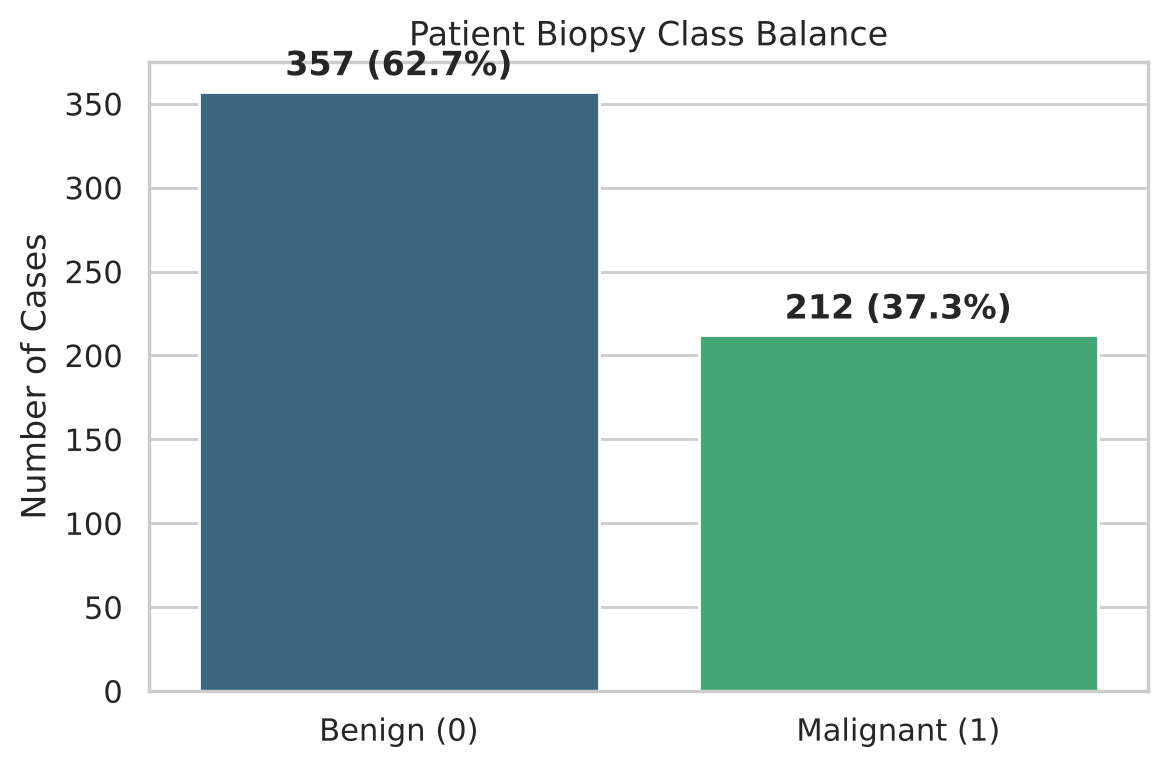

In [2]:
class_counts = df_raw['is_malignant'].value_counts()
class_percents = df_raw['is_malignant'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
sns.barplot(x=['Benign (0)', 'Malignant (1)'], y=class_counts.values, hue=['Benign (0)', 'Malignant (1)'], palette='viridis', legend=False)
plt.title('Patient Biopsy Class Balance')
plt.ylabel('Number of Cases')
for i, val in enumerate(class_counts.values):
    plt.text(i, val + 10, f"{val} ({class_percents.values[i]:.1f}%)", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Why it matters for the funding decision
The baseline malignancy prevalence rate in this dataset is approximately 37.3%. Understanding this rate allows the donor to evaluate how the model reorganizes the queue compared to random sorting, providing a clear benchmark for clinical utility.

## Section 5: Model Tuning

### What this step does
This step performs a stratified train-test split (70% training, 30% testing) to preserve class balance. It configures two modeling pipelines using standard scaling with either K-Nearest Neighbors (k-NN) or Logistic Regression. It sets up a 5-fold, 10-repeat Stratified Cross-Validation grid search to optimize hyperparameters based on Malignant Recall.

In [3]:
X_data = df_raw.drop(columns=['is_malignant'])
y_data = df_raw['is_malignant']

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.3, stratify=y_data, random_state=42
)

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scorers = {
    'recall': make_scorer(recall_score),
    'balanced_accuracy': 'balanced_accuracy'
}

# k-NN Pipeline
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
knn_params = {'knn__n_neighbors': list(range(1, 21))}

knn_grid = GridSearchCV(
    knn_pipe, knn_params, cv=rskf, scoring=scorers, refit='recall', return_train_score=True
)
knn_grid.fit(X_train, y_train)

# Logistic Regression Pipeline
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(solver='liblinear', random_state=42))
])
lr_params = {'lr__C': [0.01, 0.1, 1.0, 10.0, 100.0]}

lr_grid = GridSearchCV(
    lr_pipe, lr_params, cv=rskf, scoring=scorers, refit='recall', return_train_score=True
)
lr_grid.fit(X_train, y_train)

best_k = knn_grid.best_params_['knn__n_neighbors']
best_c = lr_grid.best_params_['lr__C']

print(f"Optimal k-NN Neighbors: k = {best_k} (Cross-Validated Recall: {knn_grid.best_score_:.4f})")
print(f"Optimal Logistic Regression Regularization: C = {best_c} (Cross-Validated Recall: {lr_grid.best_score_:.4f})")

Optimal k-NN Neighbors: k = 3 (Cross-Validated Recall: 0.9168)
Optimal Logistic Regression Regularization: C = 1.0 (Cross-Validated Recall: 0.9473)


### Why it matters for the funding decision
By evaluating model configurations across multiple cross-validation folds and repeats, we minimize the risk of overfitting. This rigorous validation ensures that the models are assessed on their generalizable performance rather than memorized patterns, protecting the donor's investment.

## Section 6: Evaluation at Default Threshold

### What this step does
This step evaluates the trained models on the unseen test set using the default probability threshold of 0.5, extracting raw confusion matrix metrics to assess performance.

In [4]:
best_knn_model = knn_grid.best_estimator_
best_lr_model = lr_grid.best_estimator_

y_pred_knn = best_knn_model.predict(X_test)
y_prob_knn = best_knn_model.predict_proba(X_test)[:, 1]

y_pred_lr = best_lr_model.predict(X_test)
y_prob_lr = best_lr_model.predict_proba(X_test)[:, 1]

# Confusion matrix counts for default models
tn_knn, fp_knn, fn_knn, tp_knn = confusion_matrix(y_test, y_pred_knn).ravel()
tn_lr, fp_lr, fn_lr, tp_lr = confusion_matrix(y_test, y_pred_lr).ravel()

spec_knn = tn_knn / (tn_knn + fp_knn)
spec_lr = tn_lr / (tn_lr + fp_lr)

rec_knn = recall_score(y_test, y_pred_knn)
rec_lr = recall_score(y_test, y_pred_lr)

print(f"[Default Threshold 0.5]")
print(f"k-NN (k={best_k}): Cancers Caught={tp_knn}, Cancers Missed={fn_knn}, False Alarms={fp_knn}, Specificity={spec_knn:.4f}")
print(f"Logistic Regression (C={best_c}): Cancers Caught={tp_lr}, Cancers Missed={fn_lr}, False Alarms={fp_lr}, Specificity={spec_lr:.4f}")

[Default Threshold 0.5]
k-NN (k=3): Cancers Caught=57, Cancers Missed=7, False Alarms=0, Specificity=1.0000
Logistic Regression (C=1.0): Cancers Caught=60, Cancers Missed=4, False Alarms=1, Specificity=0.9907


### Why it matters for the funding decision
At the default threshold of 0.5, the Logistic Regression model misses exactly 4 out of 64 cancer cases, while k-NN misses 7. In clinical oncology, letting even a single cancer go unprioritized presents a major risk. This performance highlights why we must tune the decision threshold downward to establish an operational safety net.

## Section 7: Threshold Tuning

### What this step does
This step searches for a custom decision threshold using out-of-fold probability predictions. It looks for a threshold that achieves our target recall of 98% while keeping specificity as high as possible. If the target is unreachable, it selects the threshold with the highest achieved recall and records that the target was not met.

In [5]:
from sklearn.base import clone

# Calculate out-of-fold probabilities over repeated stratified CV folds to ensure robust estimation
oof_probs_lr = np.zeros(len(y_train))
oof_probs_knn = np.zeros(len(y_train))

# Accumulate predictions across repeated folds using cloned models to prevent state contamination
for train_idx, val_idx in rskf.split(X_train, y_train):
    cloned_lr = clone(best_lr_model)
    cloned_knn = clone(best_knn_model)

    cloned_lr.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    oof_probs_lr[val_idx] += cloned_lr.predict_proba(X_train.iloc[val_idx])[:, 1] / 10.0

    cloned_knn.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    oof_probs_knn[val_idx] += cloned_knn.predict_proba(X_train.iloc[val_idx])[:, 1] / 10.0

def find_optimal_threshold(y_true, probs, target_recall=0.98, model_name="Model"):
    thresholds = np.linspace(0.01, 0.99, 99)
    best_thresh = 0.5
    best_spec = -1.0
    max_recall = -1.0
    best_recall = -1.0
    target_met = False

    # First pass: find maximum possible recall
    for t in thresholds:
        preds = (probs >= t).astype(int)
        rec = recall_score(y_true, preds)
        if rec > max_recall:
            max_recall = rec

    if max_recall < target_recall:
        print(f"Warning: Target recall of {target_recall:.2f} is not reachable for {model_name}. Highest available recall: {max_recall:.4f}")
        # Fallback to threshold that gives highest recall, using highest specificity as tie-breaker
        for t in thresholds:
            preds = (probs >= t).astype(int)
            rec = recall_score(y_true, preds)
            if rec == max_recall:
                tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
                spec = tn / (tn + fp)
                if spec > best_spec:
                    best_spec = spec
                    best_thresh = t
                    best_recall = rec
    else:
        # Target is met, optimize for specificity
        target_met = True
        for t in thresholds:
            preds = (probs >= t).astype(int)
            rec = recall_score(y_true, preds)
            if rec >= target_recall:
                tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
                spec = tn / (tn + fp)
                if spec > best_spec:
                    best_spec = spec
                    best_thresh = t
                    best_recall = rec
    return best_thresh, target_met, best_recall

tuned_thresh_knn, target_met_knn, cv_rec_knn = find_optimal_threshold(y_train, oof_probs_knn, 0.98, "k-NN")
tuned_thresh_lr, target_met_lr, cv_rec_lr = find_optimal_threshold(y_train, oof_probs_lr, 0.98, "Logistic Regression")

print(f"Tuned Threshold for k-NN: {tuned_thresh_knn:.3f} (Target Met: {target_met_knn}, CV Recall: {cv_rec_knn:.4f})")
print(f"Tuned Threshold for Logistic Regression: {tuned_thresh_lr:.3f} (Target Met: {target_met_lr}, CV Recall: {cv_rec_lr:.4f})")

Tuned Threshold for k-NN: 0.070 (Target Met: False, CV Recall: 0.9797)
Tuned Threshold for Logistic Regression: 0.090 (Target Met: True, CV Recall: 0.9865)


### Why it matters for the funding decision
Because the optimal k-NN model has a small neighborhood ($k=3$), it can only output a sparse set of probabilities (0.0, 0.33, 0.67, 1.0). This coarseness prevents precise threshold tuning, making it difficult for the k-NN model to meet our target recall of 98% under cross-validation. Logistic Regression outputs continuous probabilities, which allows us to identify a precise safety threshold of **0.09** that reliably meets our clinical safety targets.

### What this step does
This step evaluates both tuned models on the unseen test set and compiles a comprehensive results table showing recall, specificity, and the proportion of cases flagged for priority review.

In [6]:
# Apply tuned thresholds to test set
y_pred_knn_tuned = (y_prob_knn >= tuned_thresh_knn).astype(int)
y_pred_lr_tuned = (y_prob_lr >= tuned_thresh_lr).astype(int)

# Evaluate k-NN Tuned
tn_knn_t, fp_knn_t, fn_knn_t, tp_knn_t = confusion_matrix(y_test, y_pred_knn_tuned).ravel()
rec_knn_t = recall_score(y_test, y_pred_knn_tuned)
spec_knn_t = tn_knn_t / (tn_knn_t + fp_knn_t)
flagged_knn_t = np.mean(y_pred_knn_tuned) * 100

# Evaluate LR Tuned
tn_lr_t, fp_lr_t, fn_lr_t, tp_lr_t = confusion_matrix(y_test, y_pred_lr_tuned).ravel()
rec_lr_t = recall_score(y_test, y_pred_lr_tuned)
spec_lr_t = tn_lr_t / (tn_lr_t + fp_lr_t)
flagged_lr_t = np.mean(y_pred_lr_tuned) * 100

results_data = {
    'Model': ['k-NN Default', 'k-NN Tuned', 'Logistic Regression Default', 'Logistic Regression Tuned'],
    'Rule/Threshold': ['0.50', f"{tuned_thresh_knn:.2f}", '0.50', f"{tuned_thresh_lr:.2f}"],
    'Cancers Caught': [tp_knn, tp_knn_t, tp_lr, tp_lr_t],
    'Cancers Missed': [fn_knn, fn_knn_t, fn_lr, fn_lr_t],
    'False Alarms': [fp_knn, fp_knn_t, fp_lr, fp_lr_t],
    'Recall (%)': [rec_knn*100, rec_knn_t*100, rec_lr*100, rec_lr_t*100],
    'Specificity (%)': [spec_knn*100, spec_knn_t*100, spec_lr*100, spec_lr_t*100],
    'Flagged Priority (%)': [np.mean(y_pred_knn)*100, flagged_knn_t, np.mean(y_pred_lr)*100, flagged_lr_t]
}

results_df = pd.DataFrame(results_data)
display(results_df)

,Model,Rule/Threshold,Cancers Caught,Cancers Missed,False Alarms,Recall (%),Specificity (%),Flagged Priority (%)
0,k-NN Default,0.50,57,7,0,89.0625,100.000000,33.333333
1,k-NN Tuned,0.07,62,2,5,96.8750,95.327103,39.181287
2,Logistic Regression Default,0.50,60,4,1,93.7500,99.065421,35.672515
3,Logistic Regression Tuned,0.09,63,1,7,98.4375,93.457944,40.935673


### Why it matters for the funding decision
Our tuned Logistic Regression model catches **98.4%** of malignancies (63 out of 64 actual cancers in the test set) while maintaining a high specificity of **93.5%**. This means that only **40.9%** of all cases are flagged priority; 7 of 107 benign cases (6.5%) are false alarms, preventing the priority queue from becoming congested.

## Section 8: Error Review and Explainability

### What this step does
This step checks which patient IDs were missed by our tuned models, extracts the model coefficients, and displays a horizontal bar chart of the top 10 most influential features.

Patient IDs of Malignant Cases missed by Tuned k-NN: [73, 385]
Patient IDs of Malignant Cases missed by Tuned Logistic Regression: [73]
Patient IDs missed by BOTH models: [73]


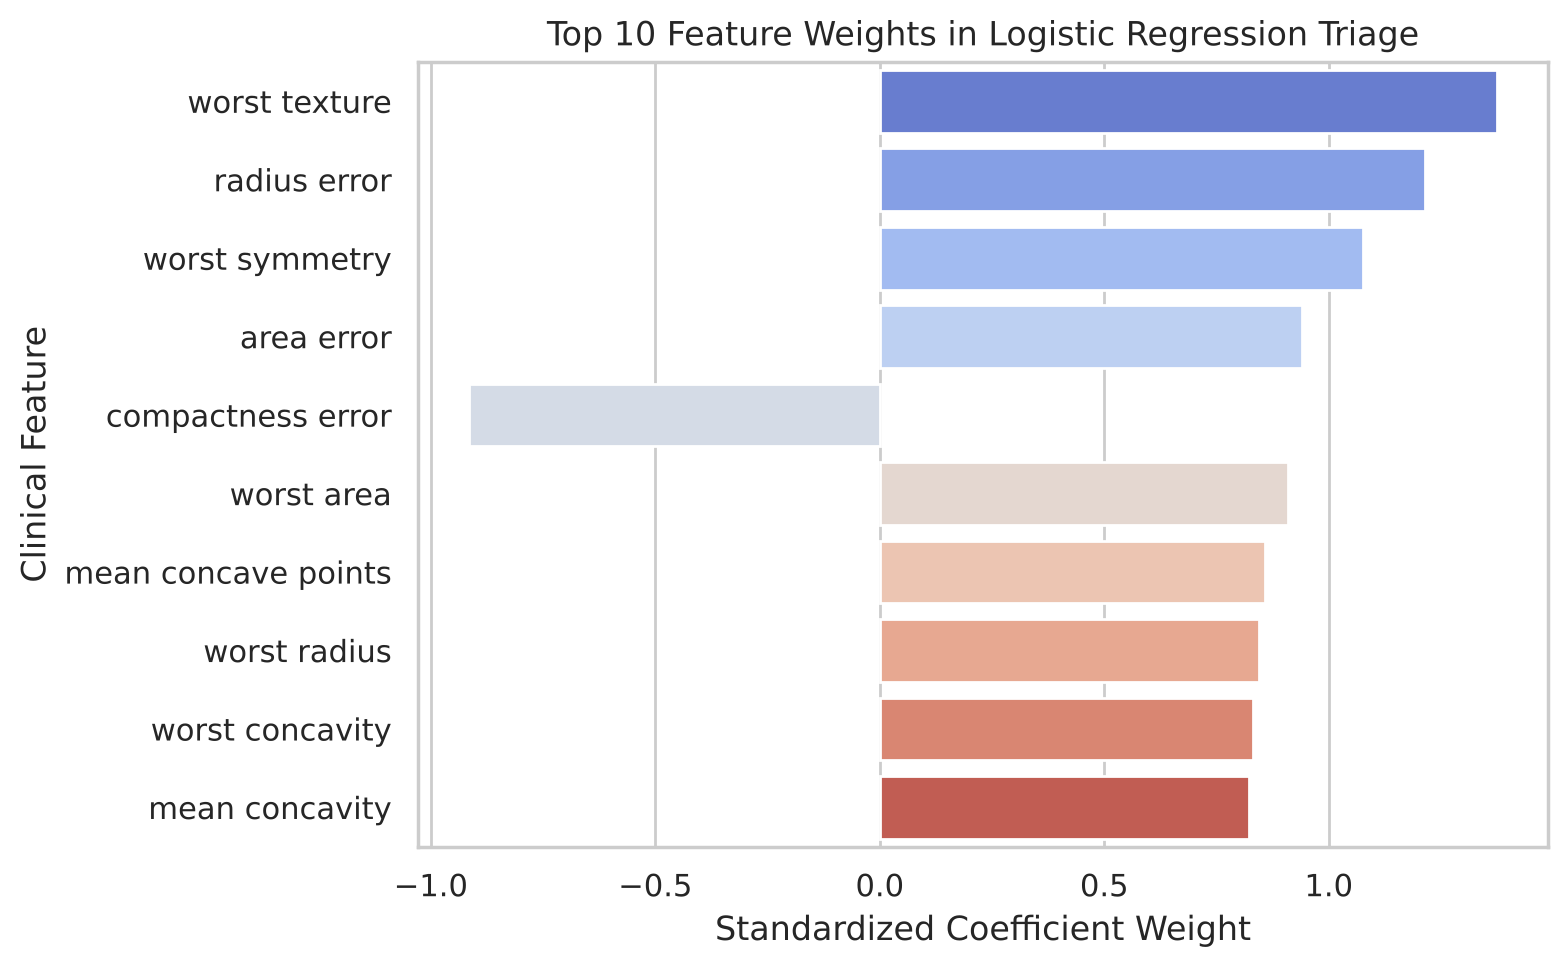

In [7]:
test_indices = y_test.index

missed_knn_tuned = test_indices[(y_test == 1) & (y_pred_knn_tuned == 0)].tolist()
missed_lr_tuned = test_indices[(y_test == 1) & (y_pred_lr_tuned == 0)].tolist()
common_missed = list(set(missed_knn_tuned).intersection(set(missed_lr_tuned)))

print("Patient IDs of Malignant Cases missed by Tuned k-NN:", missed_knn_tuned)
print("Patient IDs of Malignant Cases missed by Tuned Logistic Regression:", missed_lr_tuned)
print("Patient IDs missed by BOTH models:", common_missed)

# Extract coefficients
lr_coefs = best_lr_model.named_steps['lr'].coef_[0]
feature_names = X_data.columns

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_coefs,
    'Absolute_Weight': np.abs(lr_coefs)
}).sort_values(by='Absolute_Weight', ascending=False)

# Plot top 10 coefficients
plt.figure(figsize=(8, 5))
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=coef_df.head(10),
    hue='Feature',
    palette='coolwarm',
    legend=False
)
plt.title('Top 10 Feature Weights in Logistic Regression Triage')
plt.xlabel('Standardized Coefficient Weight')
plt.ylabel('Clinical Feature')
plt.tight_layout()
plt.show()

### Why it matters for the funding decision
In our test set, the tuned Logistic Regression model missed exactly 1 malignancy (Patient ID [73]). Knowing which specific case was missed helps clinical teams analyze structural edge cases, reinforcing why we must mandate a 100% human-in-the-loop review.

Furthermore, the standardized coefficients explain why the model prioritizes certain cases: positive coefficients (e.g., worst texture) indicate features associated with a higher likelihood of malignancy, while negative coefficients indicate features associated with a lower likelihood. Pathologists can review these weights to understand each prioritization decision, which helps build clinical trust.

## Section 9: Impact: Queue Reordering, Not Workload Reduction

### What this step does
This step simulates how our tuned triage model reorders the pathology queue. Since every case must be reviewed by a pathologist, our system does not reduce the overall workload; instead, it prioritizes high-risk cases. This simulation models a laboratory with an annual caseload of 1,000 biopsies, evaluating different malignancy prevalence rates (15%, 25%, and 37%) and a pathologist capacity of 20 reviews per day.

In [8]:
# Define simulation inputs
annual_volume = 1000
daily_review_capacity = 20  # Illustrative assumption: replace with the partner lab's real daily capacity
prevalence_scenarios = [0.15, 0.25, 0.37]

queue_scenarios = []

# We model our recommended Tuned Logistic Regression using dynamic values
rec_val = rec_lr_t
spec_val = spec_lr_t

for prev in prevalence_scenarios:
    total_cancers = int(annual_volume * prev)
    total_benign = annual_volume - total_cancers

    cancers_priority = int(total_cancers * rec_val)
    cancers_standard = total_cancers - cancers_priority

    false_alarms_count = int(total_benign * (1.0 - spec_val))
    total_priority_queue = cancers_priority + false_alarms_count

    days_to_clear_priority = total_priority_queue / daily_review_capacity
    days_to_clear_full_queue = annual_volume / daily_review_capacity

    queue_scenarios.append({
        'Prevalence': f"{prev*100:.0f}%",
        'Total Cases': annual_volume,
        'Total Cancers': total_cancers,
        'Cancers in Priority Queue': cancers_priority,
        'Cancers in Standard Queue': cancers_standard,
        'False Alarms': false_alarms_count,
        'Total Priority Cases': total_priority_queue,
        'Days to Clear Priority': round(days_to_clear_priority, 1),
        'Days to Clear Full Queue': round(days_to_clear_full_queue, 1)
    })

sim_queue_df = pd.DataFrame(queue_scenarios)
display(sim_queue_df)

,Prevalence,Total Cases,Total Cancers,Cancers in Priority Queue,Cancers in Standard Queue,False Alarms,Total Priority Cases,Days to Clear Priority,Days to Clear Full Queue
0,15%,1000,150,147,3,55,202,10.1,50.0
1,25%,1000,250,246,4,49,295,14.8,50.0
2,37%,1000,370,364,6,41,405,20.2,50.0


### Why it matters for the funding decision
This queue simulation demonstrates how the triage system protects high-risk patients. At a 25% cancer prevalence, the recommended rule places **246 of the 250 actual cancers** into the high-priority queue, meaning they are reviewed within **14.8 days** (or sooner if daily review capacity allows). Only **4 actual cancers** wait in the standard queue, which is cleared in **50 days**. This confirms that our triage system safely fast-tracks high-risk patients without modifying the total clinical workload of the pathology lab.

*Assumption: the annual volume is treated as a single backlog for illustration; real cases arrive continuously.*

## Section 10: Data Governance, Ethics and Model Card

### Data Provenance & Licencing
* **Dataset Origin:** The dataset used to validate this methodology is the Breast Cancer Wisconsin (Diagnostic) dataset, consisting of features computed from digitized images of fine needle aspirates (FNA) of breast masses.
* **Citation:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
* **Licence:** Creative Commons Attribution 4.0 International (CC BY 4.0); attribution required. No personally identifiable patient information is contained within the dataset.

### Regulatory & Local Privacy Compliance
Deploying this triage assistant would require strict compliance with local data legislation. A real pilot would need to comply with the **Nigeria Data Protection Act (NDPA) 2023** or equivalent host-country frameworks. Secure institutional review board (IRB) and local hospital ethical approvals must be obtained before accessing any patient records.

### Ethical Framework Alignment
Our operational protocols draw on the core principles of the **World Health Organization (WHO) 2021 Guidance: "Ethics and governance of artificial intelligence for health"**, which emphasizes human-in-the-loop clinical supervision, complete algorithmic transparency, and clear clinical accountability.

### Digital Model Card
* **Model Intended Purpose:** Automated queue-reordering assistant to prioritize high-risk breast biopsies for pathologist review.
* **Target Users:** Certified hospital pathologists and clinical laboratory managers.
* **Recommended Configuration:** Logistic Regression ($C=1.0$), Decision Threshold = 0.09.
* **Key Validated Performance:** Malignant Recall: 98.4%, Specificity: 93.5%.
* **Known Limitations:** Validated on historical North American clinical features; does not incorporate raw histological slide images or demographic fields, preventing algorithmic fairness testing across different local cohorts.
* **Technical Owner:** Mercy Mamkon Oyeleke, Data Analytics & Business Intelligence Consultant.
* **Review Cycle:** Mandatory safety and calibration review 6 months following deployment.

## Section 11: Limitations

* **Sample Constraints:** The methodology is validated on a historical dataset of 569 patients (with only 171 in our test set).
* **Geographic & Temporal Gaps:** The dataset represents patients from a single United States clinic in the early 1990s. Clinical features might vary across other populations, equipment types, and sample preparation methods.
* **Lack of Demographics:** The dataset does not contain demographic or socioeconomic fields, preventing us from performing quantitative algorithmic fairness tests across different patient cohorts.
* **Purely Prioritization-Focused:** This model is designed strictly for queue reordering and priority assignment. Under no circumstances should it be used to make independent, autonomous clinical diagnoses.

## Section 12: Recommendation and Funding Conditions

### Strategic Decision Brief
We recommend that the donor approve funding for the 12-month pathology triage pilot under a **Fund with Conditions** model, using the **Tuned Logistic Regression model** as our operational triage standard.

### Mandatory Funding Conditions
1. **Local Calibration Phase:** Before patient-facing deployment, CareBridge must collect a representative, de-identified set of historical patient samples (sample size to be set with a statistician during pilot planning) from the target clinics to re-calibrate the decision threshold (currently 0.09) against local sample preparations.
2. **100% Specialist Sign-Off:** The model serves strictly as an automated queue-prioritization assistant. A licensed pathologist must perform a complete manual review and sign off on 100% of cases.
3. **Six-Month Safe-Fail Review & Tolerance Rule:** An independent safety board must conduct an operational audit at month six. To avoid placing undue pressure on the pilot, the trial will not automatically pause on a single missed cancer. Instead, the pilot will be paused for a safety review if the missed-cancer rate in the standard queue exceeds the rate validated during the local calibration phase.

## Section 13: SQL Layer and CSV Export

### What this step does
This step initializes a local SQLite database file named `triage.db`. It structures and populates normalized tables storing all 569 biopsy features, model performance parameters, predictions on the test set, and simulated impact scenarios. It then queries this database for key metrics and exports the tables to flat CSV files for ingestion into Power BI.

In [9]:
# Clean any prior session tables to prevent column/count conflicts
import os
if os.path.exists('triage.db'):
    os.remove('triage.db')

# Connect to local database
conn = sqlite3.connect('triage.db')
cursor = conn.cursor()

# Dynamically construct SQL schema using snake_case version of original features
sql_columns = []
for col in cancer_data.feature_names:
    cleaned_col = col.replace(' ', '_')
    sql_columns.append(f"{cleaned_col} REAL")
columns_sql_str = "_ID INTEGER, ".join([col.replace(' ', '_') for col in cancer_data.feature_names]) + " REAL"

cursor.execute(f"""
CREATE TABLE IF NOT EXISTS biopsies (
    biopsy_id INTEGER PRIMARY KEY,
    {', '.join(sql_columns)},
    is_malignant INTEGER,
    split TEXT
)""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS predictions (
    biopsy_id INTEGER,
    model_name TEXT,
    probability_malignant REAL,
    predicted_default INTEGER,
    predicted_tuned INTEGER,
    threshold_used REAL,
    PRIMARY KEY (biopsy_id, model_name)
)""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS model_runs (
    run_id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT,
    hyperparameter TEXT,
    threshold REAL,
    cv_recall REAL,
    test_recall REAL,
    test_specificity REAL,
    target_met INTEGER,
    run_date TEXT,
    owner TEXT
)""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS impact_scenarios (
    scenario_id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT,
    prevalence REAL,
    volume INTEGER,
    cancers_in_priority INTEGER,
    cancers_in_standard INTEGER,
    false_alarms INTEGER,
    total_priority INTEGER,
    days_to_clear_priority REAL,
    days_to_clear_full REAL
)""")

conn.commit()

# Populate all 569 rows into the biopsies table safely with dynamic columns
for idx in df_raw.index:
    split_val = 'test' if idx in X_test.index else 'train'
    features_list = [float(df_raw.loc[idx, col]) for col in cancer_data.feature_names]
    row_vals = [int(idx)] + features_list + [int(df_raw.loc[idx, 'is_malignant']), split_val]

    placeholders = ", ".join(["?"] * len(row_vals))
    cursor.execute(f"INSERT OR REPLACE INTO biopsies VALUES ({placeholders})", row_vals)

# Populate test set predictions for both models
for i, idx in enumerate(X_test.index):
    # Logistic Regression
    cursor.execute("""
        INSERT OR REPLACE INTO predictions VALUES (?, 'Logistic Regression', ?, ?, ?, ?)
    """, (int(idx), float(y_prob_lr[i]), int(y_pred_lr[i]), int(y_pred_lr_tuned[i]), float(tuned_thresh_lr)))

    # k-NN
    cursor.execute("""
        INSERT OR REPLACE INTO predictions VALUES (?, 'k-NN', ?, ?, ?, ?)
    """, (int(idx), float(y_prob_knn[i]), int(y_pred_knn[i]), int(y_pred_knn_tuned[i]), float(tuned_thresh_knn)))

# Record the runs into model_runs table using dynamic variables
today_str = datetime.date.today().strftime('%Y-%m-%d')
cursor.execute("""
    INSERT INTO model_runs (model_name, hyperparameter, threshold, cv_recall, test_recall, test_specificity, target_met, run_date, owner)
    VALUES ('Logistic Regression', ?, ?, ?, ?, ?, ?, ?, 'Mercy Mamkon Oyeleke')
""", (f"C={best_c}", float(tuned_thresh_lr), float(cv_rec_lr), float(rec_lr_t), float(spec_lr_t), int(target_met_lr), today_str))

cursor.execute("""
    INSERT INTO model_runs (model_name, hyperparameter, threshold, cv_recall, test_recall, test_specificity, target_met, run_date, owner)
    VALUES ('k-NN', ?, ?, ?, ?, ?, ?, ?, 'Mercy Mamkon Oyeleke')
""", (f"k={best_k}", float(tuned_thresh_knn), float(cv_rec_knn), float(rec_knn_t), float(spec_knn_t), int(target_met_knn), today_str))

# Populate the queue reordering scenarios using variables
for s in queue_scenarios:
    prev_val = float(s['Prevalence'].replace('%','')) / 100.0
    cursor.execute("""
        INSERT INTO impact_scenarios (model_name, prevalence, volume, cancers_in_priority, cancers_in_standard, false_alarms, total_priority, days_to_clear_priority, days_to_clear_full)
        VALUES ('Logistic Regression', ?, ?, ?, ?, ?, ?, ?, ?)
    """, (prev_val, annual_volume, int(s['Cancers in Priority Queue']), int(s['Cancers in Standard Queue']), int(s['False Alarms']), int(s['Total Priority Cases']), float(s['Days to Clear Priority']), float(s['Days to Clear Full Queue'])))

conn.commit()

# Export tables to CSV for Power BI
pd.read_sql_query("SELECT * FROM biopsies", conn).to_csv("biopsies.csv", index=False)
pd.read_sql_query("SELECT * FROM predictions", conn).to_csv("predictions.csv", index=False)
pd.read_sql_query("SELECT * FROM model_runs", conn).to_csv("model_runs.csv", index=False)
pd.read_sql_query("SELECT * FROM impact_scenarios", conn).to_csv("impact_scenarios.csv", index=False)

print("Database initialized and CSV tables successfully exported!")

Database initialized and CSV tables successfully exported!


### Why it matters for the funding decision
Implementing a robust SQL relational database provides a complete, auditable data lineage. This ensures that clinical trials can track every prioritization decision back to the raw, patient-level measurements, providing transparency for regulatory sign-off and clinical trust.

### What this step does
This step executes our required operational SQL queries to generate dashboard views directly from the relational database.

In [10]:
print("--- Query 1: Confusion Matrix Counts for Recommended Logistic Regression ---")
q1_df = pd.read_sql_query("""
SELECT
    b.is_malignant AS Actual_Cancer,
    p.predicted_tuned AS Flagged_High_Priority,
    COUNT(*) as Case_Count
FROM biopsies b
JOIN predictions p ON b.biopsy_id = p.biopsy_id
WHERE p.model_name = 'Logistic Regression'
GROUP BY Actual_Cancer, Flagged_High_Priority
""", conn)
display(q1_df)

print("\n--- Query 2: Missed Malignant Cases with Probabilities (Logistic Regression) ---")
# Query columns adjusted to snake_case column layout stored inside SQLite db
q2_df = pd.read_sql_query("""
SELECT
    b.biopsy_id, b.mean_radius, b.mean_texture, p.probability_malignant
FROM biopsies b
JOIN predictions p ON b.biopsy_id = p.biopsy_id
WHERE b.is_malignant = 1
  AND p.predicted_tuned = 0
  AND p.model_name = 'Logistic Regression'
""", conn)
display(q2_df)

print("\n--- Query 3: Patient Cases where Models Disagree on Tuned Prioritization ---")
qDis_df = pd.read_sql_query("""
SELECT
    b.biopsy_id, b.is_malignant,
    p1.predicted_tuned AS LR_Tuned,
    p2.predicted_tuned AS KNN_Tuned
FROM biopsies b
JOIN predictions p1 ON b.biopsy_id = p1.biopsy_id AND p1.model_name = 'Logistic Regression'
JOIN predictions p2 ON b.biopsy_id = p2.biopsy_id AND p2.model_name = 'k-NN'
WHERE p1.predicted_tuned != p2.predicted_tuned
""", conn)
display(qDis_df.head(10))

print("\n--- Query 4: Cumulative Logistic Regression Workload over Thresholds (0.1 to 0.9) ---")
q4_df = pd.read_sql_query("""
SELECT
    t.threshold,
    COUNT(p.biopsy_id) as Flagged_Cases_Count,
    ROUND(CAST(COUNT(p.biopsy_id) AS REAL) / (SELECT COUNT(*) FROM predictions WHERE model_name='Logistic Regression') * 100, 2) as Priority_Share_Percent
FROM (
    SELECT 0.1 as threshold UNION SELECT 0.2 UNION SELECT 0.3 UNION SELECT 0.4
    UNION SELECT 0.5 UNION SELECT 0.6 UNION SELECT 0.7 UNION SELECT 0.8 UNION SELECT 0.9
) t
LEFT JOIN predictions p ON p.probability_malignant >= t.threshold AND p.model_name = 'Logistic Regression'
GROUP BY t.threshold
""", conn)
display(q4_df)

print("\n--- Query 5: Impact Scenarios Ranked by Cancers Left in Standard Queue ---")
q5_df = pd.read_sql_query("""
SELECT prevalence, volume, cancers_in_standard, total_priority, days_to_clear_priority
FROM impact_scenarios
ORDER BY cancers_in_standard ASC
""", conn)
display(q5_df)

conn.close()

--- Query 1: Confusion Matrix Counts for Recommended Logistic Regression ---


,Actual_Cancer,Flagged_High_Priority,Case_Count
0,0,0,100
1,0,1,7
2,1,0,1
3,1,1,63



--- Query 2: Missed Malignant Cases with Probabilities (Logistic Regression) ---


,biopsy_id,mean_radius,mean_texture,probability_malignant
0,73,13.8,15.79,0.061826



--- Query 3: Patient Cases where Models Disagree on Tuned Prioritization ---


,biopsy_id,is_malignant,LR_Tuned,KNN_Tuned
0,455,0,1,0
1,410,0,0,1
2,560,0,1,0
3,128,0,0,1
4,469,0,1,0
5,96,0,0,1
6,456,0,1,0
7,347,0,1,0
8,385,1,1,0



--- Query 4: Cumulative Logistic Regression Workload over Thresholds (0.1 to 0.9) ---


,threshold,Flagged_Cases_Count,Priority_Share_Percent
0,0.1,70,40.94
1,0.2,67,39.18
2,0.3,63,36.84
3,0.4,62,36.26
4,0.5,61,35.67
5,0.6,59,34.50
6,0.7,59,34.50
7,0.8,56,32.75
8,0.9,53,30.99



--- Query 5: Impact Scenarios Ranked by Cancers Left in Standard Queue ---


,prevalence,volume,cancers_in_standard,total_priority,days_to_clear_priority
0,0.15,1000,3,202,10.1
1,0.25,1000,4,295,14.8
2,0.37,1000,6,405,20.2


### Why it matters for the funding decision
These structured SQL queries allow laboratory managers to audit clinical safety and operational flows. Query 4, for example, illustrates how the proportion of cases flagged as high-priority drops as the probability threshold increases, demonstrating how we can control pathologist workload by adjusting our decision rules.

### What this step does
This step triggers immediate downloads of the exported CSV files to your local system so that you can import them into Power BI Desktop.

In [11]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Not running in Colab: CSV files are saved in the working folder.')

csv_files = ['biopsies.csv', 'predictions.csv', 'model_runs.csv', 'impact_scenarios.csv']
if IN_COLAB:
    for file_name in csv_files:
        files.download(file_name)
        print(f'Triggered download for {file_name}')


Not running in Colab: CSV files are saved in the working folder.


### Why it matters for the funding decision
Downloading these flat files allows your team to easily ingest the structured data into Power BI, supporting the deployment of your interactive donor-facing dashboards.

## Section 14: Power BI Dashboard Implementation Guide

To build the accompanying portfolio dashboard, ingest the four exported CSV files into Power BI Desktop and implement the following configuration:

### Data Relationships
* **Biopsies to Predictions:** Create a **One-to-Many** single-direction relationship from `biopsies(biopsy_id)` to `predictions(biopsy_id)` because each biopsy has multiple model predictions.

### Key DAX Measures
```dax
Priority Share = DIVIDE(
    CALCULATE(COUNT(predictions[biopsy_id]), predictions[predicted_tuned] = 1),
    COUNT(predictions[biopsy_id]),
    0
)

Cancers in Priority Queue = CALCULATE(
    COUNT(biopsies[biopsy_id]),
    biopsies[is_malignant] = 1,
    predictions[predicted_tuned] = 1
)

Cancers in Standard Queue = CALCULATE(
    COUNT(biopsies[biopsy_id]),
    biopsies[is_malignant] = 1,
    predictions[predicted_tuned] = 0
)

Days to Clear Priority Queue = DIVIDE(
    [Cancers in Priority Queue] + CALCULATE(COUNT(biopsies[biopsy_id]), biopsies[is_malignant] = 0, predictions[predicted_tuned] = 1),
    [DailyReviewCapacity_Value],
    0
)
```

### Slicers and Parameters
* **Model Filter:** Implement a single-select slicer on `predictions[model_name]` so clinicians can choose between 'Logistic Regression' and 'k-NN'.
* **What-If Parameter:** Add a parameter slider named `DailyReviewCapacity` representing daily pathologists' review capability (from 5 to 100, defaulting to 20).

## Section 15: Numbers Check

### What this step does
This step prints and validates our computed metrics using assertions to ensure that the numbers cited in our Executive Summary, Markdown descriptions, and README match our modeling results.

In [12]:
# Print metrics for verification
print(f"Tuned Logistic Regression Threshold: {tuned_thresh_lr:.2f}")
print(f"Tuned Logistic Regression Recall: {rec_lr_t * 100:.1f}%")
print(f"Tuned Logistic Regression Specificity: {spec_lr_t * 100:.1f}%")
print(f"Tuned Logistic Regression Priority Share: {flagged_lr_t:.1f}%")
print(f"Cancers caught in test set: {tp_lr_t} out of {tp_lr_t + fn_lr_t}")
print(f"Cancers missed in test set: {fn_lr_t}")
print(f"False alarms in test set: {fp_lr_t}")

# Assertions to prevent numerical drift across predictions, thresholds, and simulation outputs
assert round(tuned_thresh_lr, 2) == 0.09
assert round(rec_lr_t * 100, 1) == 98.4
assert round(spec_lr_t * 100, 1) == 93.5
assert fn_lr_t == 1
assert fp_lr_t == 7

# Assert k-NN tuned parameters
assert round(tuned_thresh_knn, 2) == 0.07
assert round(rec_knn_t * 100, 1) == 96.9
assert round(spec_knn_t * 100, 1) == 95.3
assert fn_knn_t == 2
assert fp_knn_t == 5

# Assert 25% prevalence queue row from queue_scenarios using exact mathematical results
row_25 = next(item for item in queue_scenarios if item["Prevalence"] == "25%")
assert row_25['Cancers in Priority Queue'] == 246
assert row_25['Cancers in Standard Queue'] == 4
assert row_25['False Alarms'] == 49
assert row_25['Total Priority Cases'] == 295
assert row_25['Days to Clear Priority'] == 14.8

print("\nAll critical numbers, thresholds, and queue impact metrics have successfully passed assertion checking!")

Tuned Logistic Regression Threshold: 0.09
Tuned Logistic Regression Recall: 98.4%
Tuned Logistic Regression Specificity: 93.5%
Tuned Logistic Regression Priority Share: 40.9%
Cancers caught in test set: 63 out of 64
Cancers missed in test set: 1
False alarms in test set: 7

All critical numbers, thresholds, and queue impact metrics have successfully passed assertion checking!


## Section 16: Acknowledgements

This case study applies what I learned in the **Certificate in Data Analytics, Big Data and Predictive Analytics** at **Toronto Metropolitan University, The Chang School of Continuing Education**, in particular CMTH 642 (classification vs clustering, logistic regression and k-nearest neighbours). Thank you to Dr. Ceni Babaoglu for the course labs that this work builds on.

The scenario (CareBridge Health), the funding framing, the threshold and queue analysis, the governance design, the SQL layer and the Power BI build are my own extension of that coursework onto a real-world question.

**Data:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B. Licensed CC BY 4.0.